# **FDA Regulatory Action Analysis**

**Team:** A06 | **Course:** BA780 | **Members:** Malak Taoujni, Filip Handjiski, Fan-yu Chiu, Rislyn Raja, Aryan Bajaj

**Data:** FDA Recalls (2012–2026) and FDA Compliance Actions (2008–2026)

**Source:** U.S. Food and Drug Administration, FDA Data Dashboard

**License:** Public domain (U.S. government data)

**Access:** [Recalls](https://datadashboard.fda.gov/oii/cd/recalls.htm) and [Compliance Actions](https://datadashboard.fda.gov/oii/cd/complianceactions.htm) → Export (CSV, ~69 MB and ~17 MB). The notebook loads them from shared Google Drive links.
## Problem Definition
The FDA has a limited number of inspectors, so it must choose where to focus enforcement. This project links FDA recall data (unsafe products removed from sale) with compliance action data (warning letters, seizures and injunctions) by facility ID to test whether FDA enforcement goes where product-safety problems actually happen. This matters to FDA regulators deciding where to inspect, to manufacturers managing compliance risk, and to consumers who rely on safe products.

**Phase 1 (Team Assignment):** recall trends, and recalls vs. actions by product type, state and facility, plus which products get the harshest actions (Q1 to Q5).

**Phase 2 (Final Project):** whether recalls are getting more dangerous and why they happen, how enforcement has changed, whether it follows a facility's recall count and severity, what happens to recalls after an action, and how recalls and actions compare across states (Q6 to Q15).

**Success criteria:** clear, insightful and quantitative answers to 15 questions that lead to actionable recommendations for better targeting FDA oversight.


## Executive Summary
**Objective.** The FDA must choose where to concentrate enforcement since it has a limited number of inspectors. We investigated whether FDA compliance actions, such as warning letters, seizures, and injunctions, reach the actual locations of safety issues.

**Method.** We cleaned and then linked 104,083 recall records (37,623 recall events, 2012–2026) with 177,252 compliance actions (2008–2026) by facility ID (FEI Number), then answered 15 questions across recall trends, severity, recall causes, enforcement patterns, facility-level risk and geography.

**Key findings.**
- **Recalls are getting more dangerous:** the share of recall events rated Class I (risk of serious harm or death) nearly doubled, from 10.4% in 2013 to 19.6% in 2025. Food drives this: it accounts for 61% of all Class I recalls (and 40% of food recalls are Class I), mainly from undeclared allergens, Salmonella and Listeria (58% of all Class I recalls).

- **Enforcement follows risk, but late:** facilities with more recalls are more likely to be disciplined (13.5% of facilities with 1 recall event vs. 46.4% with 100+), and actions arrive straight after a spike in recalls, after which recalls fall 63% within three years.

- **Gaps remain:** devices are 40.5% of non-tobacco recall events but only 15.2% of actions, and non-tobacco enforcement has shrunk (warning letters fell from 779 in 2011 to 500 in 2025; seizures and injunctions from 48 to 2). Several states, led by Virginia, Minnesota and Iowa, have many repeat-recall facilities but few compliance actions.

**Recommendations.** The FDA should use recall history (count and severity) as an early-warning sign to act before recall spikes, increase oversight of device makers and of food pathogen and allergen controls, and review states and facilities with high recall burden but few actions.

## Introduction & Motivation
Every year thousands of unsafe products, from contaminated food to faulty medical devices, are pulled from U.S. shelves. The FDA is the agency that both classifies these recalls and disciplines the companies behind them, but it has a limited number of inspectors and must choose where to look. If enforcement doesn't follow risk, unsafe facilities can keep producing recalls while resources go elsewhere.

**Why read this analysis?**
- **Regulators** get help with evidence from this analysis on whether enforcement targets the riskiest products and a data-driven way to prioritize inspections.
- **Manufacturers and compliance teams** learn which product types, recall causes and recall histories are most associated with FDA action.
- **Consumers and policymakers** see whether product safety is improving or getting worse.

What makes this analysis different is that it **links two FDA datasets that are usually studied separately** at the facility level, so we can test *what* is recalled and when the FDA responds.


## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## Load the Data





In [2]:
action_df = pd.read_csv("https://drive.google.com/uc?export=download&id=1qxcj1VXfY29P5UAevNNBgp1kNSkPacrL")

recall_df = pd.read_csv("https://drive.google.com/uc?export=download&id=1q-RnBUM8eJ4wtJ50E6jN5U03FAI7XhXq", low_memory=False)

## Initial look at the data
The first three rows, to get a sense of what the columns contain.

In [3]:
action_df.head(3)

,FEI Number,Legal Name,State,Country/Area,Product Type,Action Taken Date,Action Type,Case/Injunction ID
0,3049113208,Smoke Shack,New Hampshire,United States,Tobacco,09/17/2026,Warning Letter,738322
1,3030250540,Rey's Mini Market,New Jersey,United States,Tobacco,09/17/2026,Warning Letter,738323
2,3049112976,SMOKE STOP,California,United States,Tobacco,09/17/2026,Warning Letter,738324


In [4]:
recall_df.head(3)

,FEI Number,Recalling Firm Name,Product Type,Product Classification,Status,Distribution Pattern,Recalling Firm City,Recalling Firm State,Recalling Firm Country,Center Classification Date,Reason for Recall,Product Description,Event ID,Event Classification,Product ID,Center,Recall Details
0,1216677,"CooperSurgical, Inc.",Devices,Class I,Ongoing,"Nationwide distribution to CT, FL, GA, IA, IL,...",Trumbull,Connecticut,United States,09/18/2026,Potential to exhibit a loose connection betwee...,INCA (Infant Nasal Cannulae Assy) Infant Nasal...,99643,Class I,222061,CDRH,https://www.accessdata.fda.gov/scripts/ires/?P...
1,1216677,"CooperSurgical, Inc.",Devices,Class I,Ongoing,"Nationwide distribution to CT, FL, GA, IA, IL,...",Trumbull,Connecticut,United States,09/18/2026,Potential to exhibit a loose connection betwee...,INCA (Infant Nasal Cannulae Assy) Neonatal Nas...,99643,Class I,222063,CDRH,https://www.accessdata.fda.gov/scripts/ires/?P...
2,1000524567,Evergreen Fresh Sprouts LLC,Food/Cosmetics,Class I,Ongoing,Distributed in WA,Moyie Springs,Idaho,United States,09/18/2026,Salmonella,"Evergreen Fresh Sprouts LLC, Broccoli Sprouts,...",99842,Class I,222720,HFP,https://www.accessdata.fda.gov/scripts/ires/?P...


## **Data Cleaning**
### Step 1: Before cleaning
Column types, missing counts and dataset size.

In [5]:
print(f"Actions shape: {action_df.shape}")
print(f"Recall shape: {recall_df.shape}\n")

print("Actions Info:")
action_df.info()

print("\nRecalls Info:")
recall_df.info()

Actions shape: (177252, 8)
Recall shape: (104113, 17)

Actions Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177252 entries, 0 to 177251
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   FEI Number          177252 non-null  int64 
 1   Legal Name          177252 non-null  object
 2   State               177252 non-null  object
 3   Country/Area        177252 non-null  object
 4   Product Type        177252 non-null  object
 5   Action Taken Date   177252 non-null  object
 6   Action Type         177252 non-null  object
 7   Case/Injunction ID  177252 non-null  int64 
dtypes: int64(2), object(6)
memory usage: 10.8+ MB

Recalls Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104113 entries, 0 to 104112
Data columns (total 17 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   FEI Number                  104113 

### Step 2: Find hidden missing values
The FDA uses "-" for blanks, so we change it to NaN before counting and so that it is recognizable to pandas.

In [6]:
recall_df = recall_df.replace('-', np.nan)
action_df = action_df.replace('-', np.nan)

print('Missing values in recall_df:', recall_df.isnull().sum())

print('\nMissing values in action_df:', action_df.isnull().sum())

Missing values in recall_df: FEI Number                      30
Recalling Firm Name              0
Product Type                     0
Product Classification           0
Status                           0
Distribution Pattern             2
Recalling Firm City              4
Recalling Firm State          5376
Recalling Firm Country           6
Center Classification Date       0
Reason for Recall               76
Product Description              1
Event ID                         0
Event Classification             0
Product ID                       0
Center                           0
Recall Details                   0
dtype: int64

Missing values in action_df: FEI Number               0
Legal Name               0
State                 2278
Country/Area             2
Product Type             0
Action Taken Date        0
Action Type              0
Case/Injunction ID       0
dtype: int64


### Step 3: Handle missing values
Dropped 30 rows with no FEI Number. Filled missing states with "No US State" (foreign firms) and anything else with "Unknown".

In [7]:
rows_before = len(recall_df)
recall_df = recall_df.dropna(subset=['FEI Number'])  # Drop rows where FEI number is empty
recall_df['FEI Number'] = recall_df['FEI Number'].astype('int64') # Convert FEI from text to whole number
print('Rows dropped (no FEI Number):', rows_before - len(recall_df))

recall_df['Recalling Firm State'] = recall_df['Recalling Firm State'].fillna('No US State')  # No state = foreign firm
action_df['State'] = action_df['State'].fillna('No US State')
print('Recalls labeled "No US State":', (recall_df['Recalling Firm State'] == 'No US State').sum())
print('Actions labeled "No US State":', (action_df['State'] == 'No US State').sum())

recall_df = recall_df.fillna('Unknown') # Anything else still missing
action_df = action_df.fillna('Unknown')

print('Missing values left in recall_df:', recall_df.isnull().sum().sum())
print('Missing values left in action_df:', action_df.isnull().sum().sum())

Rows dropped (no FEI Number): 30
Recalls labeled "No US State": 5374
Actions labeled "No US State": 2278
Missing values left in recall_df: 0
Missing values left in action_df: 0


### Step 4: Fix dates and add Year

Dates were stored as text, so we convert them and pull out the year for trend analysis.

In [8]:
recall_df['Center Classification Date'] = pd.to_datetime(recall_df['Center Classification Date'])
action_df['Action Taken Date'] = pd.to_datetime(action_df['Action Taken Date'])

recall_df['Year'] = recall_df['Center Classification Date'].dt.year
action_df['Year'] = action_df['Action Taken Date'].dt.year

recall_df[['Center Classification Date', 'Year']].head(3)


,Center Classification Date,Year
0,2026-09-18,2026
1,2026-09-18,2026
2,2026-09-18,2026


### Step 5: Check duplicates

In [9]:
print('Duplicate rows in recall_df:', recall_df.duplicated().sum())
print('Duplicate rows in action_df:', action_df.duplicated().sum())


Duplicate rows in recall_df: 0
Duplicate rows in action_df: 0


### Step 6: After cleaning
No missing values left, and the dates and FEI Number now have the correct types.

In [10]:
# Check that no missing values are left
print('Missing values left in recalls:', recall_df.isnull().sum().sum())
print('Missing values left in actions:', action_df.isnull().sum().sum())
print('FEI Number type:', recall_df['FEI Number'].dtype)
print('Date type:', recall_df['Center Classification Date'].dtype)

# How many facilities appear in both datasets?
both = set(recall_df['FEI Number']) & set(action_df['FEI Number'])
print('Facilities in both datasets:', len(both))


Missing values left in recalls: 0
Missing values left in actions: 0
FEI Number type: int64
Date type: datetime64[ns]
Facilities in both datasets: 1724


### Step 7: Check for outliers
We count recall events per facility to look for unusually high values.

In [11]:
# One recall event can have many products, so keep one row per recall event
events = recall_df.drop_duplicates(subset='Event ID').copy()
print('Product rows:', len(recall_df))
print('Recall events:', len(events))

# Recall events per facility
recalls_per_facility = events.groupby('FEI Number').size()
print('\nRecall events per facility (summary):')
print(recalls_per_facility.describe())

print('\nTop 5 facilities by number of recall events:')
print(recalls_per_facility.sort_values(ascending=False).head())

Product rows: 104083
Recall events: 37623

Recall events per facility (summary):
count    10231.000000
mean         3.677353
std         11.979952
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        317.000000
dtype: float64

Top 5 facilities by number of recall events:
FEI Number
2240869    317
2126677    281
1417572    254
1417592    247
1070196    237
dtype: int64


One recall event can encompass several goods (104,083 product rows vs. 37,623 recall events), but the recall file contains one product per row. Therefore, recall events (Event ID) are now counted instead of product rows. There are 317 recall events at one facility (Siemens Medical Solutions USA), whereas the majority have only 1-2 (median 1). We kept these outliers because they represent actual valuable data instead of errors in the data. Since the same facility may appear under several spellings, we count by FEI Number instead of company name.

### Step 8: Join the two datasets by FEI Number
We count recall events and actions per facility and join them into one table, which we use in Q4, Q11, Q12 and Q15.

In [12]:
recall_counts = pd.DataFrame({'Recall Count': events['FEI Number'].value_counts()})
action_counts = pd.DataFrame({'Action Count': action_df['FEI Number'].value_counts()})

# Join the two tables by FEI Number
facility_df = recall_counts.join(action_counts)

# Facilities with no actions get 0
facility_df = facility_df.fillna(0)
facility_df['Had Action'] = facility_df['Action Count'] > 0

print(facility_df['Had Action'].value_counts())
facility_df.head()

Had Action
False    8507
True     1724
Name: count, dtype: int64


,Recall Count,Action Count,Had Action
FEI Number,,,
2240869,317,0.0,False
2126677,281,0.0,False
1417572,254,1.0,True
1417592,247,2.0,True
1070196,237,0.0,False


### Data Dictionary
| Dataset | Column | Meaning | Type |
|---|---|---|---|
| Both | FEI Number | Unique FDA facility ID (links the datasets) | int |
| Recalls | Product Type | Devices, Food/Cosmetics, Drugs, Biologics, Veterinary, Tobacco | text |
| Recalls | Product Classification | Severity: Class I (most serious), II, III | text |
| Recalls | Event ID | One recall event (can cover several products) | int |
| Recalls | Recalling Firm State | U.S. state ("No US State" = foreign firm) | text |
| Recalls | Center Classification Date | Date the FDA classified the recall | datetime |
| Compliance | Product Type | Product area (94% Tobacco) | text |
| Compliance | Action Type | Warning Letter, Seizure, Injunction | text |
| Compliance | State | U.S. state ("No US State" = foreign firm) | text |
| Compliance | Action Taken Date | Date of the action | datetime |
| Both | Year | Year taken from the date (added by us) | int |

### Cleaning Process Log

| Dataset | Column | Issue | Action | Justification |
|---|---|---|---|---|
| Both | All | "-" used instead of blanks | Replaced with NaN | So pandas counts them as missing |
| Recalls | FEI Number | 30 missing, stored as text | Dropped rows, converted to integer | Needed to link datasets; <0.03% of rows |
| Both | State | 5,374 recall / 2,278 action values missing | Filled "No US State" | Mostly foreign firms |
| Recalls | City, Country, Reason, Description, Distribution | 89 missing | Filled "Unknown" | Tiny share; keep rows |
| Both | Dates | Stored as text | Converted to datetime, added Year | Needed for trends over time |
| Both | All | Duplicates checked | None found | Each row is unique |
| Recalls | Recalls per facility | Outliers (max 317 recall events vs. median 1) | Kept | Real repeat offenders |
| Recalls | Firm Name | Same facility spelled differently | Counted by FEI Number | Avoids double counting |
| Both | FEI Number | Two separate datasets | Joined into facility_df | Compare recalls vs. actions per facility |
| Recalls | Event ID | One recall event spans several product rows (104,083 rows vs. 37,623 events) | Counted each Event ID once | So we count recalls, not products |
> **So what:** The data was mostly complete. We have 104,083 recall product rows (37,623 recall events) and 177,252 actions with no missing values after correcting "-" values and date types. Additionally, 1,724 facilities are present in both datasets.


## **Part 1 — Team Assignment Summary**
We cleaned both datasets, connected them by facility ID, and gave answers to five initial questions in the first phase. Key findings:


| # | Question | Key findings |
|---|---|---|
| Q1 | How have recalls changed over time? | Recall events peaked at 3,652 in 2013; low of 2,015 in 2022 |
| Q2 | Do product types with the most recalls get the most actions? | No: devices = 40.5% of recall events but 15.2% of non-tobacco actions |
| Q3 | Do states with the most recalls get the most actions? | Mostly; CA leads both, but NJ, MA and MN are under-enforced relative to recalls |
| Q4 | Do facilities that ever had an action have more recalls? | Yes: 49.4% of facilities that had an action at some point had 2+ recall events vs. 34.5% of those that never did (median is 1 in both groups) |
| Q5 | Which products get the harshest actions? | Food/Cosmetics: 57.6% of all seizures and injunctions |


These lead to the questions in Part 2: Why do recalls happen, are they getting more dangerous, and does enforcement respond to the riskiest facilities, and if yes then when?


### Q1: How has the number of FDA recalls changed from 2012 to 2026?
**Who cares:** FDA regulators, to see whether product-safety problems are growing or shrinking over time.

Year
2012    2399
2013    3652
2014    2914
2015    2670
2016    3048
2017    2673
2018    2943
2019    2614
2020    2470
2021    2132
2022    2015
2023    2204
2024    2241
2025    2102
2026    1546
dtype: int64


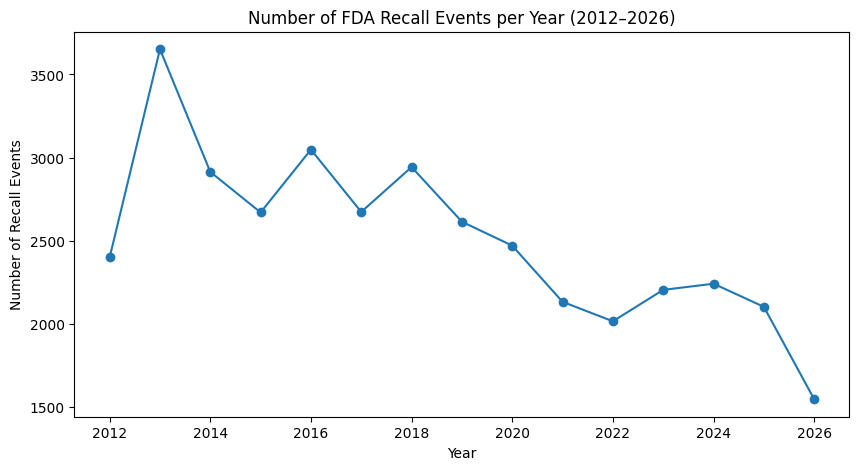

In [13]:
# Count recall events (not product rows) per year
recalls_per_year = events.groupby('Year').size()
print(recalls_per_year)

recalls_per_year.plot(kind='line', marker='o', figsize=(10, 5), title='Number of FDA Recall Events per Year (2012–2026)')
plt.xlabel('Year')
plt.ylabel('Number of Recall Events')
plt.show()

> **So what:** Recall events peaked at 3,652 in 2013 and have generally declined since, reaching a low of 2,015 in 2022. 2026's count is not a true decline because it only runs until September.

> **Caveat:** 2012 and 2026 are partial years (data runs June 2012 – Sept 2026), and part of the 2020–22 decline may reflect COVID-era slowdowns instead of safer products.

### Q2: Leaving out tobacco, do the product types with the most recall events also have the most FDA actions?
**Who cares:** FDA regulators, because this comparison helps show where recall activity and regulatory actions are concentrated.

                Recall events  FDA actions
Product Type                              
Biologics                22.9          2.3
Devices                  40.5         15.2
Drugs                    12.7         33.8
Food/Cosmetics           21.5         38.8
Veterinary                2.4          9.8


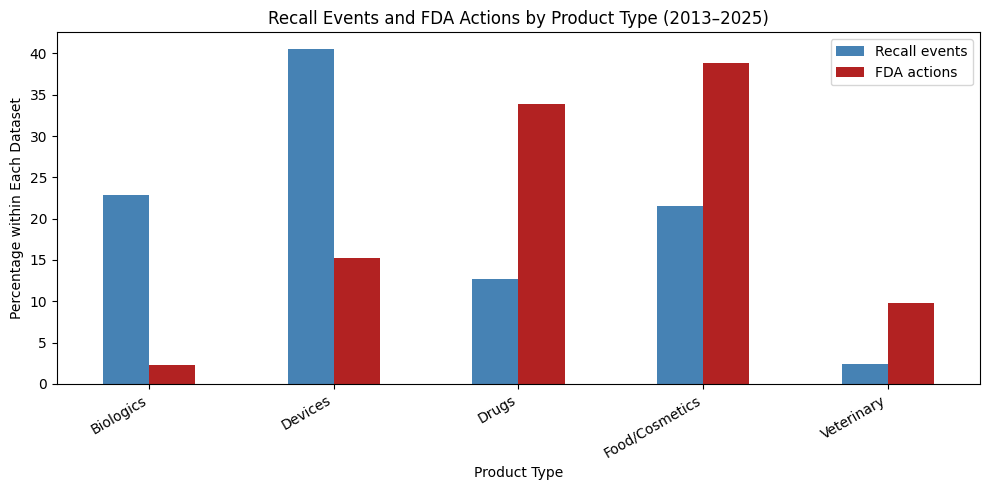

In [14]:
# Keep 2013–2025 and leave out tobacco
actions = action_df[
    (action_df["Action Taken Date"].dt.year.between(2013, 2025)) &
    (action_df["Product Type"] != "Tobacco")
]

recalls = recall_df[
    (recall_df["Center Classification Date"].dt.year.between(2013, 2025)) &
    (recall_df["Product Type"] != "Tobacco")
]

# One recall event can have several product rows, so count it once
recalls = recalls.drop_duplicates(subset="Event ID")

# Count each product type
recall_counts = recalls["Product Type"].value_counts()
action_counts = actions["Product Type"].value_counts()

# Turn the counts into percentages
recall_percent = recall_counts / recall_counts.sum() * 100
action_percent = action_counts / action_counts.sum() * 100

# Put the two percentages side by side
comparison = pd.DataFrame({
    "Recall events": recall_percent,
    "FDA actions": action_percent
})

print(comparison.round(1))

# Make the chart
comparison.plot(kind="bar", figsize=(10, 5), color=["steelblue", "firebrick"])
plt.title("Recall Events and FDA Actions by Product Type (2013–2025)")
plt.xlabel("Product Type")
plt.ylabel("Percentage within Each Dataset")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

  > **So what:** Devices had the largest share of recall events (40.5%), while Food/Cosmetics had the largest share of FDA actions (38.8%). The product type with the most recalls was different from the one with the most actions.

  > **Caveat:** Many recalls are voluntary, so a recall doesn't necessarily lead to FDA action.

### Q3: Leaving out tobacco, do the states with the most recall events also have the most FDA actions?
**Who cares:** FDA regulators, to see whether inspections and actions are focused on the same states where recalls happen most.

               Recall events  FDA actions
California              12.6         16.7
New Jersey               7.4          4.4
Florida                  7.0          8.5
Pennsylvania             5.8          3.8
Illinois                 5.7          3.2
New York                 5.5          8.2
Texas                    5.0          7.8
Massachusetts            4.8          2.0
Ohio                     4.0          2.6
Minnesota                3.9          1.6


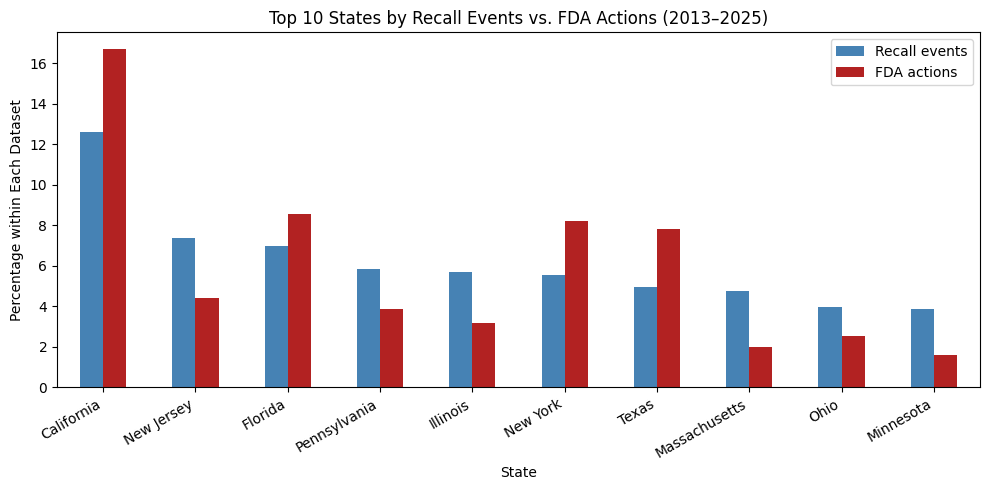

In [15]:
# Keep 2013–2025, leave out tobacco and firms with no US state
state_recalls = recall_df[
    (recall_df["Year"].between(2013, 2025)) &
    (recall_df["Product Type"] != "Tobacco") &
    (recall_df["Recalling Firm State"] != "No US State")
]

state_actions = action_df[
    (action_df["Year"].between(2013, 2025)) &
    (action_df["Product Type"] != "Tobacco") &
    (action_df["State"] != "No US State")
]

# One recall event can have several product rows, so count it once
state_recalls = state_recalls.drop_duplicates(subset="Event ID")

# Count each state and turn into percentages
recall_state_pct = state_recalls["Recalling Firm State"].value_counts() / len(state_recalls) * 100
action_state_pct = state_actions["State"].value_counts() / len(state_actions) * 100

# Put the two side by side and keep the top 10 states by recall events
state_comparison = pd.DataFrame({
    "Recall events": recall_state_pct,
    "FDA actions": action_state_pct
}).fillna(0)

top_states = state_comparison.sort_values("Recall events", ascending=False).head(10)
print(top_states.round(1))

# Make the chart
top_states.plot(kind="bar", figsize=(10, 5), color=["steelblue", "firebrick"])
plt.title("Top 10 States by Recall Events vs. FDA Actions (2013–2025)")
plt.xlabel("State")
plt.ylabel("Percentage within Each Dataset")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

> **So what:** California leads both, with 12.6% of recall events and 16.7% of FDA actions. Some states don't match: New Jersey, Massachusetts and Minnesota have a much larger share of recalls than actions, while New York, Texas and Florida have a larger share of actions than recalls.

>**Caveat:** Firms are counted by headquarters state, which may not be where the problem product was made or sold exactly.

### Q4: Do facilities that ever had a compliance action have more recalls than those that never did?
**Who cares:** FDA regulators, to see whether facilities that were warned or penalized are also the ones with repeated safety problems.

                             Facilities  Median recalls  Average recalls
Group                                                                   
Had an action at some point        1724             1.0              5.7
Never had an action                8507             1.0              3.3
Group         Had an action at some point  Never had an action
Recall Range                                                  
1                                    50.6                 65.5
2–5                                  34.1                 25.5
6–20                                 10.0                  6.5
21+                                   5.3                  2.4


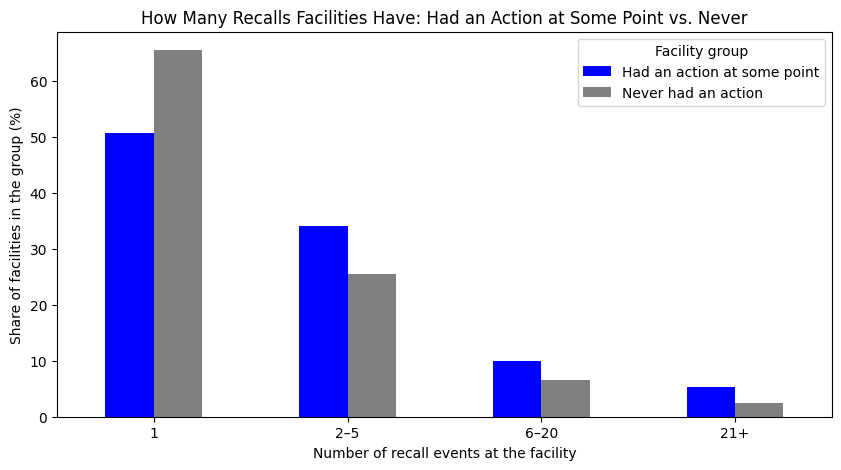

In [16]:
# Label each facility: had an action at some point vs. never had one
facility_df['Group'] = np.where(facility_df['Had Action'], 'Had an action at some point', 'Never had an action')

# Number of facilities, median and average recall events in each group
summary = facility_df.groupby('Group')['Recall Count'].agg(['count', 'median', 'mean']).round(1)
summary.columns = ['Facilities', 'Median recalls', 'Average recalls']
print(summary)

# The data is skewed, so compare how recall events are spread in each group
facility_df['Recall Range'] = pd.cut(facility_df['Recall Count'], bins=[0, 1, 5, 20, 10000],
                                     labels=['1', '2–5', '6–20', '21+'])
distribution = pd.crosstab(facility_df['Recall Range'], facility_df['Group'], normalize='columns') * 100
print(distribution.round(1))

distribution.plot(kind='bar', figsize=(10, 5), color=['blue', 'gray'])
plt.title('How Many Recalls Facilities Have: Had an Action at Some Point vs. Never')
plt.xlabel('Number of recall events at the facility')
plt.ylabel('Share of facilities in the group (%)')
plt.xticks(rotation=0)
plt.legend(title='Facility group')
plt.show()

> **So what:** Yes, recall counts are highly skewed: a few facilities with hundreds of recalls raise the averages (5.7 vs. 3.3), whereas the average facility in both groups has just one recall event (median 1 vs. 1). They are twice as likely to have 21+ recall events (5.3% vs. 2.4%), and 49.4% of the 1,724 facilities that had an action at some time had more than one recall event, compared to 34.5% of the 8,507 facilities that never had one.

> **Caveat:** The groups compare "ever" vs. "never", so recalls before and after the action are both counted. This shows a link, not whether the action caused or followed the recalls (Q13 looks at timing).

### Q5: Apart from tobacco, which product types get the harshest FDA actions (seizures and injunctions)?
**Who cares:** FDA regulators, to see which product categories draw the most serious enforcement, and companies in those categories, who face the highest compliance risk.



Action Type     Injunction  Seizure
Product Type                       
Food/Cosmetics         131       51
Drugs                   48       24
Veterinary              32        1
Devices                 20        5
Biologics                3        1

Share of all harsh actions (%):
Product Type
Food/Cosmetics    57.6
Drugs             22.8
Veterinary        10.4
Devices            7.9
Biologics          1.3
dtype: float64


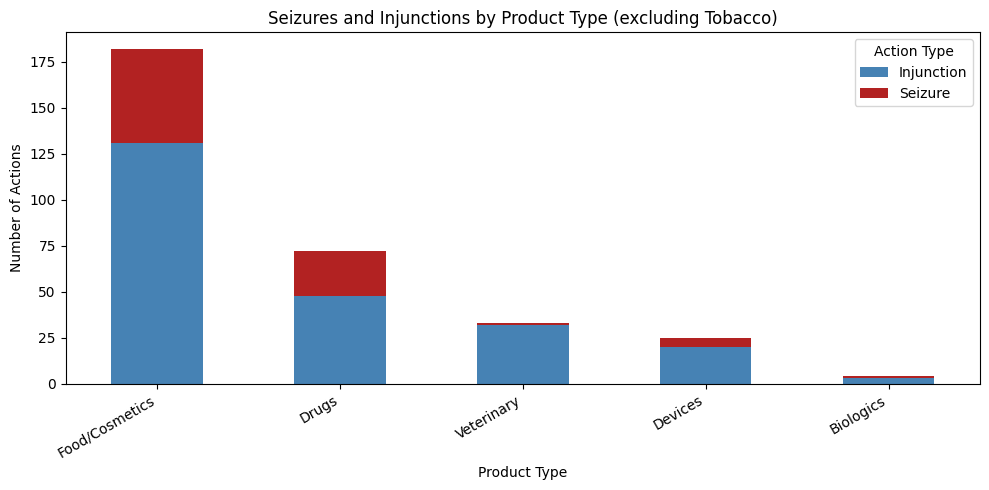

In [17]:
# Leave out tobacco and keep only the harshest actions
harsh = action_df[
    (action_df["Product Type"] != "Tobacco") &
    (action_df["Action Type"].isin(["Injunction", "Seizure"]))
]

# Count actions by product type (bars) and action type (stacks)
harsh_counts = pd.crosstab(harsh["Product Type"], harsh["Action Type"])

# Sort so the product type with the most harsh actions comes first
harsh_counts = harsh_counts.loc[harsh_counts.sum(axis=1).sort_values(ascending=False).index]
print(harsh_counts)
print("\nShare of all harsh actions (%):") # Calculating percentages
print((harsh_counts.sum(axis=1) / harsh_counts.sum().sum() * 100).round(1))

# Stacked bar chart
harsh_counts.plot(kind="bar", stacked=True, figsize=(10, 5), color=["steelblue", "firebrick"])
plt.title("Seizures and Injunctions by Product Type (excluding Tobacco)")
plt.xlabel("Product Type")
plt.ylabel("Number of Actions")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Action Type")
plt.tight_layout()
plt.show()

> **So what:** Food/Cosmetics received the harshest FDA actions with 182 of the 316 seizures and injunctions (57.6%), followed by Drugs (22.8%) and Veterinary (10.4%).

>**Caveat:** Seizures and injunctions are rare (316 in total), so a few cases can shift these percentages a lot.

## **Part 2 — Deeper Analysis**
Part 2 goes deeper in four sections:
1. **Recall severity and causes (Q6–Q9):** Are recalls becoming more serious, and what causes them?
2. **Enforcement patterns (Q10):** How has FDA enforcement outside tobacco changed over time?
3. **Facility-level risk (Q11–Q13):** Does enforcement follow a facility's recall count and severity, and what happens to recalls after an action?
4. **Geography (Q14–Q15):** Which recall problems are common in each state, and which states are under-enforced?

## 2.1 Recall Severity and Causes


### Q6: Are recalls becoming more dangerous over time?
**Who cares:** FDA regulators and consumers, because Class I recalls involve a substantial chance of serious harm or even death.


Year
2013    10.4
2014    13.8
2015    14.9
2016    18.1
2017    15.2
2018    11.0
2019    11.8
2020    11.3
2021    14.8
2022    15.3
2023    13.9
2024    16.2
2025    19.6
Name: count, dtype: float64
Year
2013    380
2025    412
Name: count, dtype: int64


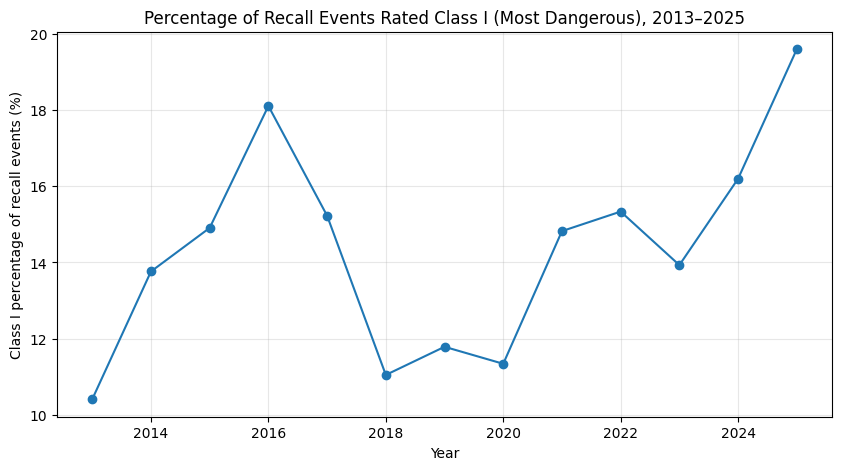

In [18]:
# Keep full years only
full_years = events[(events['Year'] >= 2013) & (events['Year'] <= 2025)]

# Count all recall events per year, and Class I events per year
all_per_year = full_years['Year'].value_counts().sort_index()
class1_events = full_years[full_years['Event Classification'] == 'Class I']
class1_per_year = class1_events['Year'].value_counts().sort_index()

# Class I percentage per year (%)
class1_share = class1_per_year / all_per_year * 100
print(class1_share.round(1))
print(class1_per_year.loc[[2013, 2025]])

class1_share.plot(kind='line', marker='o', figsize=(10, 5))
plt.title('Percentage of Recall Events Rated Class I (Most Dangerous), 2013–2025')
plt.xlabel('Year')
plt.ylabel('Class I percentage of recall events (%)')
plt.grid(alpha=0.3)
plt.show()



> **So what:** Yes. The percentage of Class I recall events nearly **doubled, from 10.4% in 2013 to 19.6% in 2025**. This is not just because total recalls fell (Q1, from 3,652 to 2,102 events): the number of Class I recalls also rose, from 380 to 412. Fewer recalls happen overall, but more of them are the most dangerous kind.

> **Caveat:** The FDA assigns severity, so changes in how it classifies recalls could affect this trend.

### Q7: Which product types produce the most dangerous recalls?
**Who cares:** FDA regulators picking which product centers need the most attention, and companies evaluating their risk.


                Class I recalls  Share of all Class I (%)  \
Product Type                                                
Food/Cosmetics             3251                      60.9   
Devices                     989                      18.5   
Drugs                       654                      12.2   
Veterinary                  421                       7.9   
Biologics                    27                       0.5   

                Class I rate within type (%)  
Product Type                                  
Food/Cosmetics                          40.3  
Devices                                  6.6  
Drugs                                   13.9  
Veterinary                              47.5  
Biologics                                0.3  


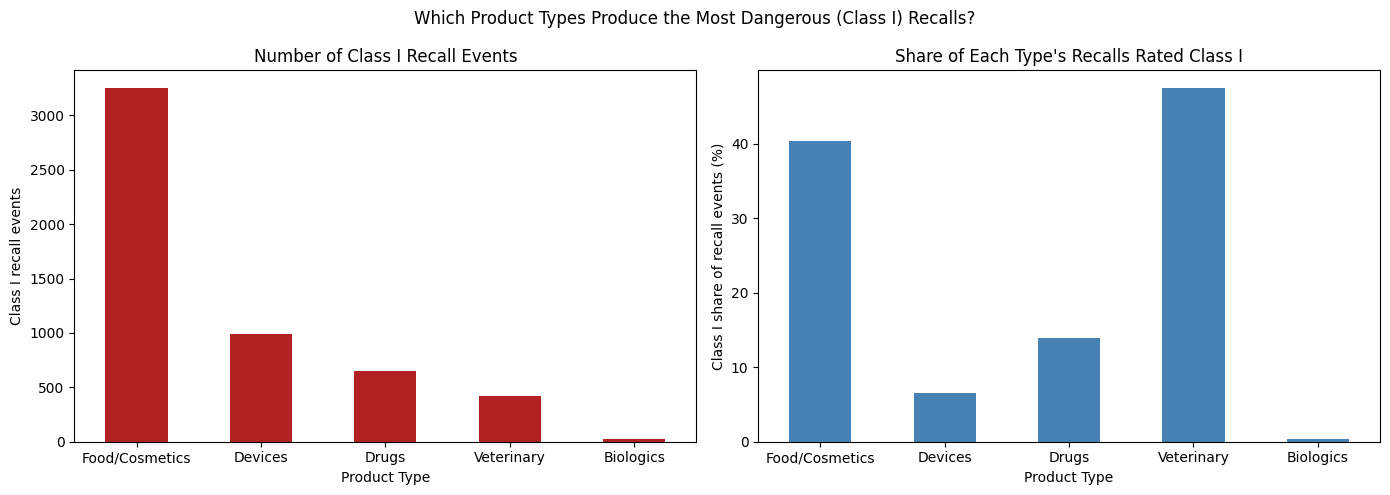

In [19]:
# Remove tobacco since it has only 4 recall events
events_no_tob = events[events['Product Type'] != 'Tobacco']
class1_events = events_no_tob[events_no_tob['Event Classification'] == 'Class I']

# Number of Class I recalls per product type, and each type's share of all Class I recalls
class1_count = class1_events['Product Type'].value_counts()
class1_share_all = class1_count / class1_count.sum() * 100

# % of each product type's own recalls that are Class I (same order as the count chart)
class1_rate = class1_count / events_no_tob['Product Type'].value_counts() * 100
class1_rate = class1_rate[class1_count.index]

print(pd.DataFrame({'Class I recalls': class1_count,
                    'Share of all Class I (%)': class1_share_all.round(1),
                    'Class I rate within type (%)': class1_rate.round(1)}))

# Two charts side by side: how many dangerous recalls vs. how likely a recall is dangerous
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

class1_count.plot(kind='bar', ax=axes[0], color='firebrick')
axes[0].set_title('Number of Class I Recall Events')
axes[0].set_xlabel('Product Type')
axes[0].set_ylabel('Class I recall events')
axes[0].tick_params(axis='x', rotation=0)

class1_rate.plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title("Share of Each Type's Recalls Rated Class I")
axes[1].set_xlabel('Product Type')
axes[1].set_ylabel('Class I share of recall events (%)')
axes[1].tick_params(axis='x', rotation=0)

plt.suptitle('Which Product Types Produce the Most Dangerous (Class I) Recalls?')
plt.tight_layout()
plt.show()

> **So what:** Food/Cosmetics is the main source of dangerous recalls: 3,251 Class I recall events, 61% of all Class I recalls, and 40.3% of its recalls are Class I. Devices are second by count (989, 19%) even though only 6.6% of device recalls are Class I, because devices have so many recalls. Veterinary has the highest Class I rate (47.5%) but only 421 events (8%) because it is a small category. This helps explain Q2 and Q5: the FDA's harshest actions go to food, which produces the most dangerous recalls, while devices, the second-largest source of Class I recalls, receive only the third-highest share of FDA actions (15.2%).

> **Caveat:** Class I counts describe recall events, not the number of people actually affected.

### Q8: What are the most common reasons for recalls?

**Who cares:** Manufacturers and FDA regulators who want to understand common product problems and identify areas for prevention.

Reason Group
Other                             36.8
Blood donor screening             12.3
Labeling error                     9.3
Failed specification/testing       9.2
Undeclared allergen                7.9
Sterility issue                    5.6
Device failure/defect              5.6
Foreign material                   3.3
Software issue                     3.1
Salmonella                         2.8
Listeria                           2.5
Manufacturing deviation (cGMP)     1.3
Name: count, dtype: float64


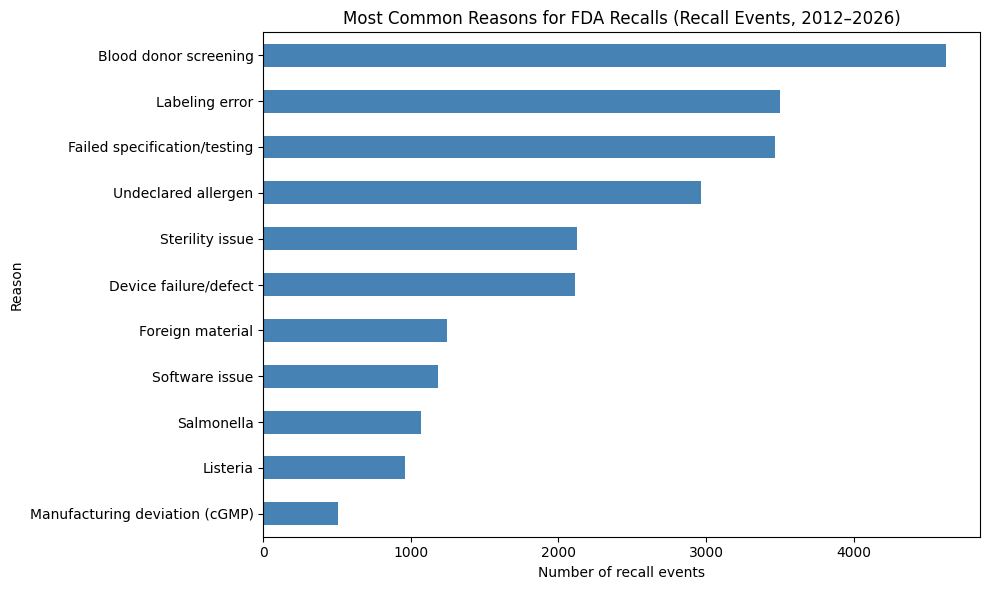

In [20]:
# Keywords for each recall reason group (checked from top to bottom; the first match wins)
reason_keywords = {
    'Listeria': ['listeria'],
    'Salmonella': ['salmonella'],
    'Undeclared allergen': ['undeclared', 'allergen'],
    'Sterility issue': ['steril'],
    'Foreign material': ['foreign', 'metal fragment', 'glass', 'plastic'],
    'Blood donor screening': ['donor'],
    'Software issue': ['software'],
    'Labeling error': ['label'],
    'Failed specification/testing': ['specification', 'impurit', 'particulate', 'stability', 'potency', 'dissolution'],
    'Manufacturing deviation (cGMP)': ['cgmp', 'good manufacturing', 'deviation'],
    'Device failure/defect': ['fail', 'malfunction', 'crack', 'break', 'defect'],
}

# Return the first group whose keyword appears in the recall reason
def reason_group(text):
    text = str(text).lower()
    for group in reason_keywords:
        for word in reason_keywords[group]:
            if word in text:
                return group
    return 'Other'

events['Reason Group'] = events['Reason for Recall'].apply(reason_group)

# % of recall events in each group
reason_counts = events['Reason Group'].value_counts()
print((reason_counts / len(events) * 100).round(1))

# Chart without 'Other', smallest at the bottom
reason_counts = reason_counts.drop('Other').sort_values()
reason_counts.plot(kind='barh', figsize=(10, 6), color='steelblue')
plt.title('Most Common Reasons for FDA Recalls (Recall Events, 2012–2026)')
plt.xlabel('Number of recall events')
plt.ylabel('Reason')
plt.tight_layout()
plt.show()


> **So what:** The leading causes, which are mostly process mistakes rather than contamination, include blood donor screening (12.3%), labeling errors (9.3%), failed testing (9.2%), and undeclared allergens (7.9%). Although they are less common, pathogens (Salmonella 2.8%, Listeria 2.5%) influence severity (Q9).

> **Caveat:** Reasons are free text, so our keyword groups are approximate; 36.8% of events did not match a group and are labeled "Other".


### Q9: Which product types does each recall reason come from, and what drives Class I recalls?
**Who cares:** FDA product centers (food, drugs, devices), to see which problems belong to which industry and which ones cause the most dangerous recalls.

Product Type                    Biologics  Devices  Drugs  Food/Cosmetics  \
Reason Group                                                                
Blood donor screening               100.0      0.0    0.0             0.0   
Device failure/defect                 4.0     84.0    8.0             4.0   
Failed specification/testing         31.0     16.0   48.0             1.0   
Foreign material                      0.0     18.0   29.0            50.0   
Labeling error                       20.0     43.0   17.0            18.0   
Listeria                              0.0      1.0    0.0            95.0   
Manufacturing deviation (cGMP)        6.0      6.0   81.0             5.0   
Salmonella                            0.0      0.0    0.0            85.0   
Software issue                        5.0     95.0    0.0             0.0   
Sterility issue                       9.0     55.0   33.0             0.0   
Undeclared allergen                   1.0      0.0    6.0            93.0   

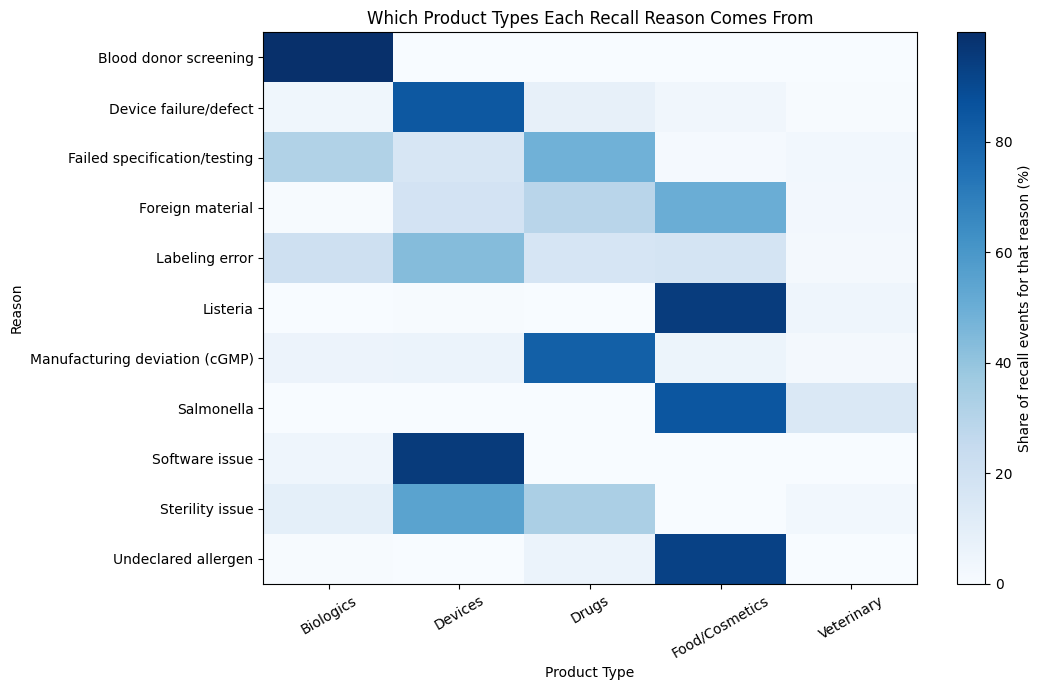

In [21]:
# Remove tobacco and the 'Other' group from Q8
grouped = events[(events['Product Type'] != 'Tobacco') & (events['Reason Group'] != 'Other')]

# % of each reason coming from each product type (each row adds to 100)
heat = pd.crosstab(grouped['Reason Group'], grouped['Product Type'], normalize='index') * 100
print(heat.round(0))

# Which reasons cause the most Class I recalls?
class1 = events[events['Event Classification'] == 'Class I']
print('\nTop reasons behind Class I recalls (%):')
print((class1['Reason Group'].value_counts(normalize=True) * 100).round(1).head(5))

plt.figure(figsize=(11, 7))
plt.imshow(heat, cmap='Blues', aspect='auto')
plt.colorbar(label='Share of recall events for that reason (%)')
plt.xticks(range(len(heat.columns)), heat.columns, rotation=30)
plt.yticks(range(len(heat.index)), heat.index)
plt.title('Which Product Types Each Recall Reason Comes From')
plt.xlabel('Product Type')
plt.ylabel('Reason')
plt.tight_layout()
plt.show()

> **So what:** Each recall reason mostly comes from one product type. Listeria (95%), undeclared allergens (93%) and Salmonella (85%) come from food, software issues (95%) and device failures (84%) come from devices, and donor screening is all biologics. Three food problems, **undeclared allergens (26.4%), Salmonella (17.6%) and Listeria (14.1%), cause 58% of all Class I recalls**. This explains Q7: food recalls are the most dangerous mostly because of these three problems.

> **Caveat:** This is based on our keyword groups from Q8, so some recalls may be in the wrong group, and 24.8% of Class I recalls are still labeled "Other".

## 2.2 Enforcement Patterns

### Q10: How has FDA enforcement changed over time, outside of tobacco?

**Who cares:** FDA regulators and company compliance teams who want to understand how enforcement activity has changed over time.

Action Type  Injunction  Seizure  Warning Letter
Year                                            
2011                 30       18             779
2025                  2        0             500


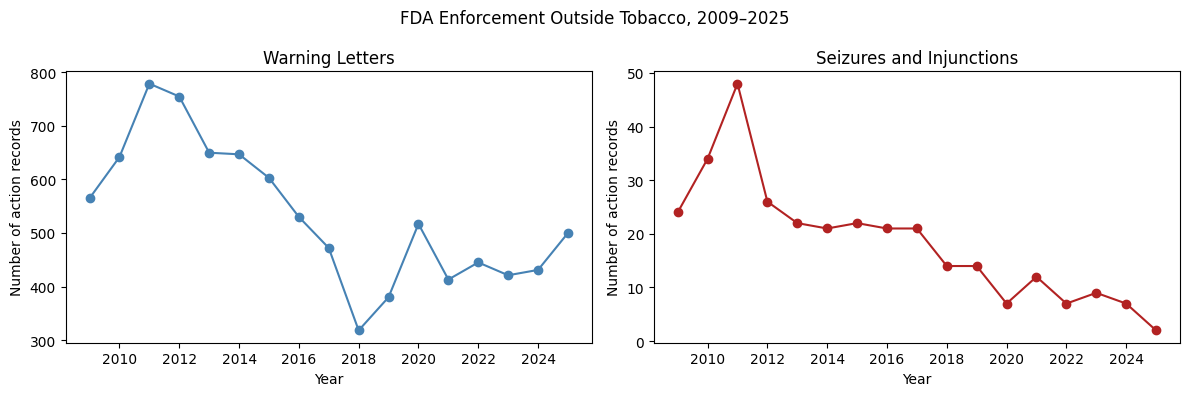

In [22]:
# Remove tobacco
actions = action_df[action_df["Product Type"] != "Tobacco"].copy()

# Get the year and keep complete calendar years
actions["Year"] = pd.to_datetime(actions["Action Taken Date"]).dt.year
actions = actions[actions["Year"].between(2009, 2025)]

# Count each action type by year
action_counts = pd.crosstab(actions["Year"], actions["Action Type"])
action_counts = action_counts.reindex(range(2009, 2026), fill_value=0)
print(action_counts.loc[[2011, 2025]])

# Facet two charts
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

action_counts["Warning Letter"].plot(
    ax=axes[0], marker="o", color="steelblue"
)
axes[0].set_title("Warning Letters")
axes[0].set_ylabel("Number of action records")

serious_actions = action_counts["Seizure"] + action_counts["Injunction"]
serious_actions.plot(ax=axes[1], marker="o", color="firebrick")
axes[1].set_title("Seizures and Injunctions")
axes[1].set_ylabel("Number of action records")

plt.suptitle("FDA Enforcement Outside Tobacco, 2009–2025")
plt.tight_layout()
plt.show()

> **So what:** Outside tobacco, warning letters fluctuated over time, while seizures and injunctions generally declined. Warning letters peaked at 779 in 2011 and reached 500 in 2025. Seizures and injunctions combined fell from 48 in 2011 to 2 in 2025.

> **Caveat:** These figures count action records, not unique companies. Fewer actions do not necessarily mean safer products. Only complete calendar years, 2009–2025, are included.

## 2.3 Facility-Level Risk

### Q11: Are facilities with more recalls more likely to receive an FDA action?
**Who cares:** FDA inspectors building a risk-based inspection list.

Recall Group
1         6448
2–5       2756
6–20       728
21–100     271
100+        28
Name: count, dtype: int64
Recall Group
1         13.5
2–5       21.3
6–20      23.6
21–100    28.8
100+      46.4
Name: Had Action, dtype: float64


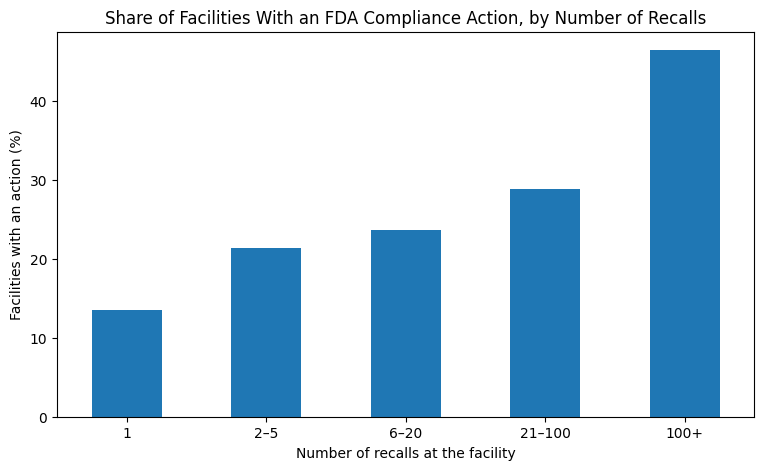

In [23]:
# Put facilities into groups by how many recalls they had
facility_df['Recall Group'] = pd.cut(facility_df['Recall Count'],
                                     bins=[0, 1, 5, 20, 100, 10000],
                                     labels=['1', '2–5', '6–20', '21–100', '100+'])

# Number of facilities in each group
print(facility_df['Recall Group'].value_counts(sort=False))

# % of facilities in each group that had an action
action_rate = facility_df.groupby('Recall Group', observed=True)['Had Action'].mean() * 100
print(action_rate.round(1))

action_rate.plot(kind='bar', figsize=(9, 5))
plt.title('Share of Facilities With an FDA Compliance Action, by Number of Recalls')
plt.xlabel('Number of recalls at the facility')
plt.ylabel('Facilities with an action (%)')
plt.xticks(rotation=0)
plt.show()

> **So what:** Yes, and steadily. Only 13.5% of facilities with a single recall event received an action, rising to 23.6% for 6–20 events and 46.4% for facilities with 100+ events. However, even among the 28 facilities with 100+ recall events, more than half (53.6%) never received a compliance action, which shows room for a more systematic, risk-based approach.

> **Caveat:** Large facilities make more products, so recall counts partly reflect size, not only risk.

### Q12: Are facilities with a Class I (most dangerous) recall more likely to be disciplined?
**Who cares:** FDA inspectors, to check whether enforcement reflects how dangerous a facility's recalls are, not just how many.

Had Class I
False    6888
True     3343
Name: count, dtype: int64
Had Class I
Had a Class I recall         20.0
Only Class II/III recalls    15.3
Name: Had Action, dtype: float64


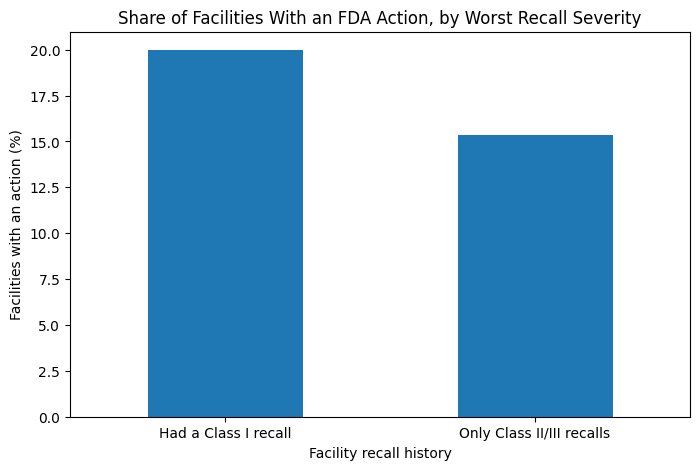

In [24]:
# True if the recall event is Class I
events['Is Class I'] = events['Event Classification'] == 'Class I'

# For each facility: True if it had at least one Class I recall
facility_df['Had Class I'] = events.groupby('FEI Number')['Is Class I'].max()

# Number of facilities in each group
print(facility_df['Had Class I'].value_counts())

# Percentage of facilities in each group that had an action
severity_rate = facility_df.groupby('Had Class I')['Had Action'].mean() * 100
severity_rate = severity_rate.rename(index={True: 'Had a Class I recall', False: 'Only Class II/III recalls'})
severity_rate = severity_rate.sort_index()
print(severity_rate.round(1))

severity_rate.plot(kind='bar', figsize=(8, 5))
plt.title('Share of Facilities With an FDA Action, by Worst Recall Severity')
plt.xlabel('Facility recall history')
plt.ylabel('Facilities with an action (%)')
plt.xticks(rotation=0)
plt.show()

> **So what:** Only slightly. 20.0% of facilities with at least one Class I recall received an action, compared with 15.3% of facilities with only Class II/III recalls. Severity matters far less than recall count (Q11): a facility with a dangerous recall is barely more likely to be disciplined than one with only minor recalls.

> **Caveat:** Some Class I recalls are handled successfully through the recall itself, without needing a separate compliance action.

### Q13: What happens to a facility's recalls before and after its first FDA action?
**Who cares:** FDA leadership, to see whether enforcement comes before problems or after them, and whether recalls go down afterwards.


Facilities: 735
Years From Action
-3    0.16
-2    0.18
-1    0.44
 0    0.54
 1    0.40
 2    0.29
 3    0.20
Name: count, dtype: float64


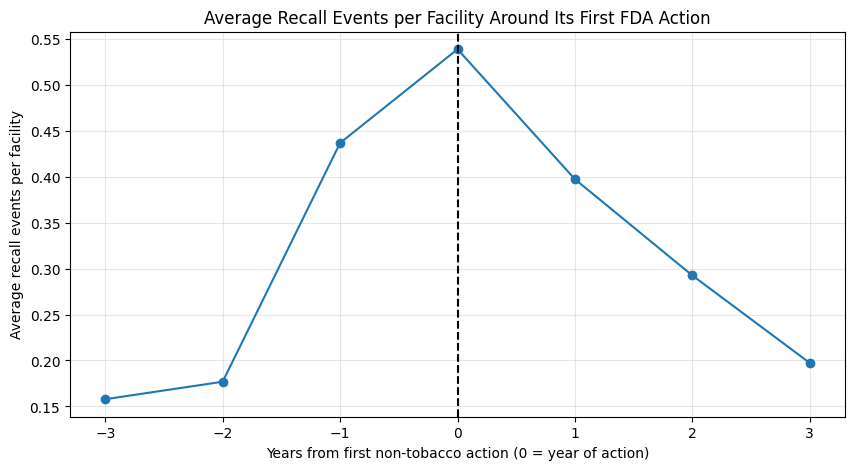

In [25]:
# Remove tobacco
non_tob_actions = action_df[action_df['Product Type'] != 'Tobacco']

# Year of each facility's first non-tobacco action
first_action = non_tob_actions.groupby('FEI Number')['Year'].min()

# Keep facilities first acted on in 2015–2022, so we can see 3 years before and after
first_action = first_action[(first_action >= 2015) & (first_action <= 2022)]

# Keep only facilities that also had recalls
first_action = first_action[first_action.index.isin(events['FEI Number'])]
num_facilities = len(first_action)
print('Facilities:', num_facilities)

# For each recall at these facilities, how many years from the first action?
study = events[events['FEI Number'].isin(first_action.index)].copy()
study['First Action Year'] = study['FEI Number'].map(first_action)
study['Years From Action'] = study['Year'] - study['First Action Year']

# Keep 3 years before to 3 years after, then average per facility
study = study[(study['Years From Action'] >= -3) & (study['Years From Action'] <= 3)]
avg_recalls = study['Years From Action'].value_counts().sort_index() / num_facilities
print(avg_recalls.round(2))

avg_recalls.plot(kind='line', marker='o', figsize=(10, 5))
plt.axvline(0, color='black', linestyle='--')
plt.title('Average Recall Events per Facility Around Its First FDA Action')
plt.xlabel('Years from first non-tobacco action (0 = year of action)')
plt.ylabel('Average recall events per facility')
plt.grid(alpha=0.3)
plt.show()

> **So what:** Recalls go up before the FDA acts and go down after. For the **735** facilities first acted on in 2015–2022, recalls rose from **0.16 per facility** three years before the action to a peak of **0.54** in the action year, then fell to **0.20** three years later, **63% lower than the peak**. This means the FDA usually acts after recalls have already spiked, which is what Q4's caveat pointed to.

> **Caveat:** This shows timing, not cause. Facilities might fix their problems on their own after a bad year, and we can't link a specific recall to a specific action.

## 2.4 Geography

### Q14: Which kinds of recall problems does each state specialize in?
**Who cares:** FDA inspectors would care because identifying which types of recall problems are most common in each state could help them target inspections, identify recurring safety issues, and prioritize resources to prevent future product recalls.

Reason Group          Contamination  Device / software issues  \
Recalling Firm State                                            
California                     26.2                      18.6   
New Jersey                     16.8                      10.5   
New York                       22.9                      10.1   
Illinois                       18.5                      17.4   
Florida                        24.0                       9.4   
Pennsylvania                   11.3                      28.2   
Texas                          23.4                       9.3   
Massachusetts                  10.9                      34.3   
Minnesota                      18.6                      27.2   
Ohio                           24.0                      22.4   

Reason Group          Labeling / allergens  Manufacturing concerns  \
Recalling Firm State                                                 
California                            36.9                     9.6   
New Jerse

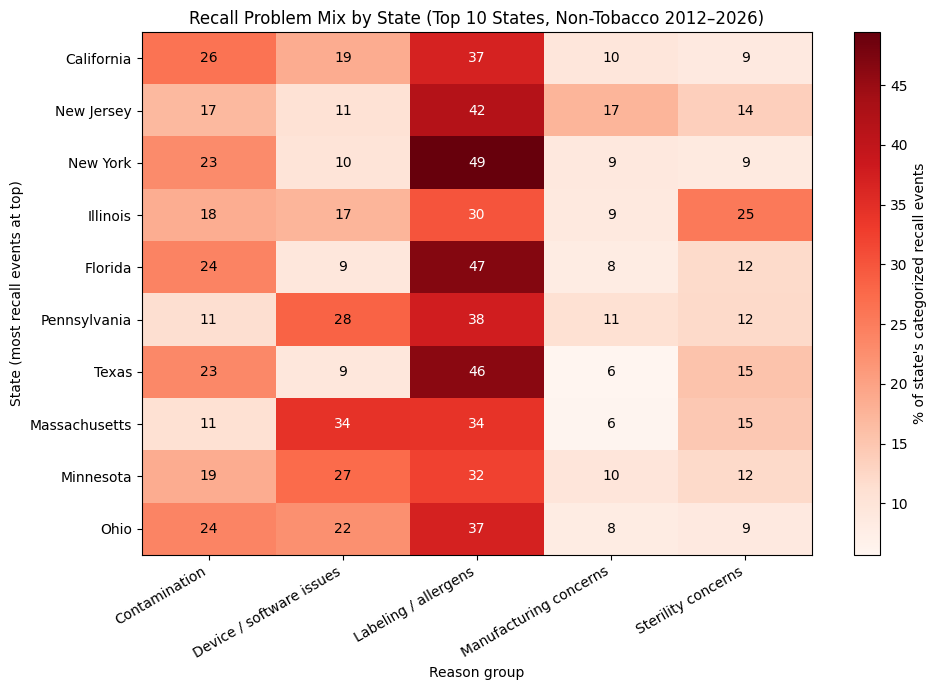

In [26]:
rec = events[(events['Year'].between(2012, 2026)) &
             (events['Product Type'] != 'Tobacco') &
             (events['Recalling Firm State'] != 'No US State')].copy()

# Group similar recall descriptions using keywords
def group_reason(reason):
    reason = str(reason).lower()

    if "steril" in reason:
        return "Sterility concerns"
    elif any(word in reason for word in
             ["contamin", "listeria", "salmonella", "bacteria", "mold"]):
        return "Contamination"
    elif any(word in reason for word in
             ["label", "undeclared", "allergen"]):
        return "Labeling / allergens"
    elif any(word in reason for word in
             ["software", "device", "malfunction"]):
        return "Device / software issues"
    elif any(word in reason for word in
             ["manufactur", "gmp", "cgmp"]):
        return "Manufacturing concerns"
    else:
        return "Other reasons"

# Use grouping
rec['Reason Group'] = rec['Reason for Recall'].apply(group_reason)

# Count each recall event once per reason group
ev = rec.drop_duplicates(['Event ID', 'Reason Group'])

# Select top 10 states by recall events; dropping the vague "Other reasons" category
top10 = ev.drop_duplicates('Event ID')['Recalling Firm State'].value_counts().head(10).index
ev = ev[ev['Recalling Firm State'].isin(top10) & (ev['Reason Group'] != 'Other reasons')]

# Make table of recall events by state and reason
table = pd.crosstab(ev['Recalling Firm State'], ev['Reason Group'])

# Convert counts to percentages
share = table.div(table.sum(axis=1), axis=0) * 100

# Sort states by total number of categorized recall events
share = share.loc[table.sum(axis=1).sort_values(ascending=False).index]

print(share.round(1))

# Make heatmap
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(share.values, cmap='Reds', aspect='auto')

# Labels for x and y
ax.set_xticks(range(len(share.columns)))
ax.set_xticklabels(share.columns, rotation=30, ha='right')
ax.set_yticks(range(len(share.index)))
ax.set_yticklabels(share.index)

# Write the % in each cell (change text color for readability based on cell color)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        val = share.values[i, j]
        ax.text(j, i, f'{val:.0f}', ha='center', va='center',
                color='white' if val > share.values.max() * 0.6 else 'black')

# Add colorbar and chart titles
plt.colorbar(im, ax=ax, label="% of state's categorized recall events")
plt.title('Recall Problem Mix by State (Top 10 States, Non-Tobacco 2012–2026)')
plt.xlabel('Reason group')
plt.ylabel('State (most recall events at top)')

# Display graph
plt.tight_layout()
plt.show()

> **So What:** Recall problems vary a lot between states. Labeling/allergen issues account for nearly half of categorized recalls in New York (49.4%), Florida (46.7%), and Texas (46.3%), while device/software issues make up 34.3% in Massachusetts and 28.2% in Pennsylvania. These differences could help FDA inspectors tailor inspections and prevention efforts to the most common problems in each state.

> **Caveat:** These percentages show the mix of recall reasons, not the actual level of risk or number of recalls in each state. Differences may reflect the types of products manufactured locally, industry concentration, or reporting practices rather than necessarily differences in safety or inspection effectiveness.

### Q15: Which states are under-enforced relative to their recall burden?
**Who cares:** FDA inspectors and enforcement policymakers would care because identifying states where recall burdens rank much higher than compliance-action rates could help them investigate potential enforcement gaps and determine where additional oversight or resources may be needed.

                      facilities  repeat_rate  action_rate   gap
Recalling Firm State                                            
Wisconsin                    201         43.8         15.4  55.6
Iowa                          94         39.4         12.8  61.1
Georgia                      202         40.1         13.9  61.1
Minnesota                    256         50.0         15.6  63.9
Virginia                     109         48.6         14.7  66.7


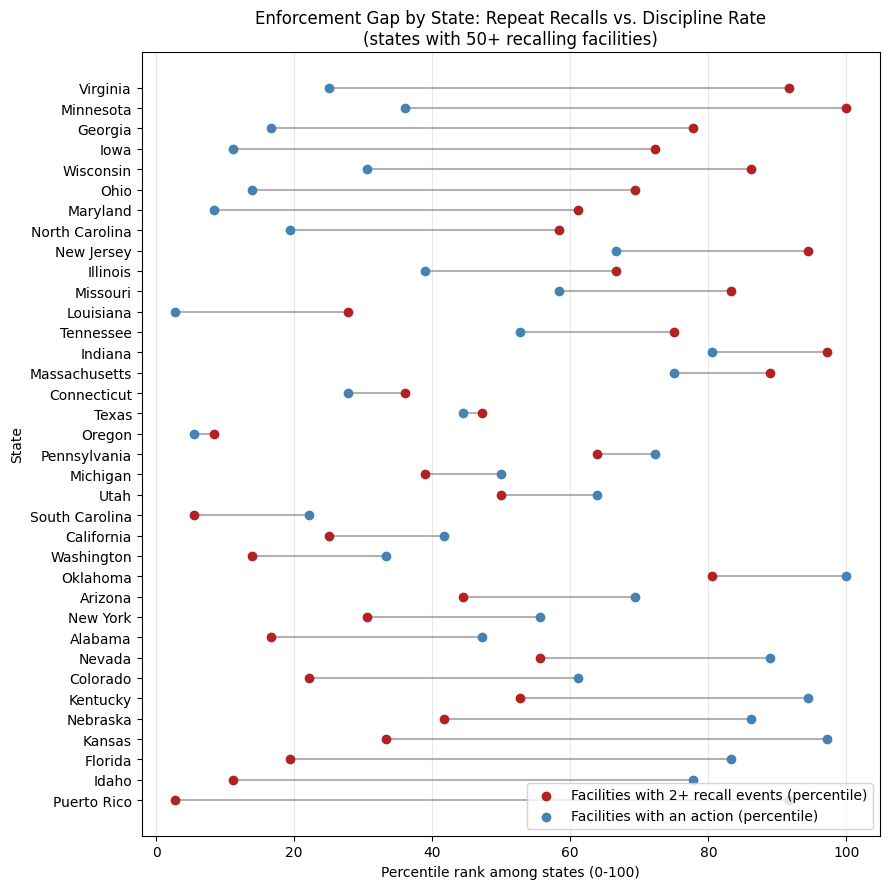

In [27]:
# Identify the state of each facility (non-tobacco, U.S. states only)
fac_state = (events[events['Product Type'] != 'Tobacco']
             .drop_duplicates('FEI Number')[['FEI Number', 'Recalling Firm State']]
             .set_index('FEI Number'))

# Connect the state to the facility table
f = facility_df.join(fac_state, how='inner')
f = f[f['Recalling Firm State'] != 'No US State']

# Recall counts are skewed, so measure recall burden as the share of facilities with repeat recalls (2+ events)
f['Repeat Recalls'] = f['Recall Count'] > 1

# Recall burden and enforcement for each state
by_state = f.groupby('Recalling Firm State').agg(
    facilities=('Recall Count', 'size'),
    repeat_rate=('Repeat Recalls', 'mean'),
    action_rate=('Had Action', 'mean'))
by_state['repeat_rate'] *= 100
by_state['action_rate'] *= 100

# Keep states with at least 50 recalling facilities
by_state = by_state[by_state['facilities'] >= 50]

# Convert both to percentile ranks so they can share one axis
by_state['recall_pct'] = by_state['repeat_rate'].rank(pct=True) * 100
by_state['action_pct'] = by_state['action_rate'].rank(pct=True) * 100

# Enforcement gap = recall percentile - action percentile
by_state['gap'] = by_state['recall_pct'] - by_state['action_pct']
by_state = by_state.sort_values('gap')
print(by_state[['facilities', 'repeat_rate', 'action_rate', 'gap']].round(1).tail(5))

fig, ax = plt.subplots(figsize=(9, 9))
y = np.arange(len(by_state))
ax.hlines(y, by_state['action_pct'], by_state['recall_pct'], color='gray', alpha=0.6)
ax.scatter(by_state['recall_pct'], y, color='firebrick', zorder=3, label='Facilities with 2+ recall events (percentile)')
ax.scatter(by_state['action_pct'], y, color='steelblue', zorder=3, label='Facilities with an action (percentile)')
ax.set_yticks(y)
ax.set_yticklabels(by_state.index)
ax.set_title('Enforcement Gap by State: Repeat Recalls vs. Discipline Rate\n(states with 50+ recalling facilities)')
ax.set_xlabel('Percentile rank among states (0-100)')
ax.set_ylabel('State')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


> **So What:** Virginia has the largest enforcement gap (66.7 percentile points): 48.6% of its facilities had repeat recalls, but only 14.7% received a compliance action. Minnesota (63.9 points; 50.0% repeat recalls vs. 15.6% with an action), Iowa and Georgia (61.1 points each) follow. These states may warrant closer review to check whether enforcement is keeping pace with repeat recalls.

> **Caveat:** We use the share of facilities with repeat recalls instead of average recalls because recall counts are very skewed. A large gap does not prove under-enforcement: rankings are relative, and product mix, violation seriousness and inspection practices may explain some of the difference.

## Conclusion
Recalls are getting more dangerous (Class I share 10.4% → 19.6%, 2013–2025), while non-tobacco enforcement has shrunk (warning letters 779 → 500 and seizures/injunctions 48 → 2, 2011–2025). Enforcement follows recall volume (action rate 13.5% → 46.4% as recall events rise) but barely reflects severity (20.0% vs. 15.3%), and it usually arrives after recalls peak.

**Recommendations**
1. **Early-warning sign:** flag facilities with rising or Class I recalls so action comes before the peak. *(Impact: High / Feasibility: High)*
2. **Food pathogens and allergens:** they cause 58% of Class I recalls, so focus food inspections there. *(Impact: High / Feasibility: Medium)*
3. **Device oversight:** devices are 40.5% of recall events but only 15.2% of actions. *(Impact: High / Feasibility: Medium)*
4. **High-recall facilities:** 53.6% of facilities with 100+ recall events were never disciplined. *(Impact: Medium / Feasibility: High)*

**Limitations and next steps:** Results show correlations, not causes. Adding inspection and facility-size data would allow testing the early-warning sign on past years.

## Challenges
| Challenges | Impact | How we handled it |
|---|---|---|
| Hidden missing values written as "-" | `isnull()` showed almost no missing data | Replaced "-" with NaN before counting and cleaning |
| Missing facility IDs (FEI Number) and text-formatted IDs | Couldn't link 30 recalls; join would fail | Dropped the 30 rows (<0.03%) and converted FEI to int |
| One recall event spread across many product rows (104,083 rows vs. 37,623 events) | Counting rows counts products, not recalls | Counted each `Event ID` once in every question and in the facility table |
| Skewed recall counts (median 1, max 317 recall events per facility) | Averages are pulled up by a few facilities | Reported medians, group sizes and the spread (Q4); used the share of facilities with repeat recalls (Q15) |
| Tobacco = 94% of compliance actions | Hid all other enforcement patterns | Excluded tobacco when comparing product types, states and enforcement trends |
| Partial years (June 2012, Sept 2026) | Distorted year-over-year trends | Used full years for trend charts |
| Same facility under different company-name spellings | Double counting by name | Grouped everything by FEI Number instead of company name |
| Free-text recall reasons | No ready-made category column | Built keyword-based reason groups; reported the 36.8% "Other" share openly |
| No direct link between a recall and an action | Couldn't prove an action responded to a recall | Used facility-level timing (Q13) and described results as associations |

## References
- U.S. Food and Drug Administration. *FDA Data Dashboard – Recalls.* https://datadashboard.fda.gov/oii/cd/recalls.htm (accessed Sept 2026)
- U.S. Food and Drug Administration. *FDA Data Dashboard – Compliance Actions.* https://datadashboard.fda.gov/oii/cd/complianceactions.htm (accessed Sept 2026)
- U.S. Food and Drug Administration. *Recalls Background and Definitions* (Class I, II, III). https://www.fda.gov/safety/industry-guidance-recalls/recalls-background-and-definitions
- pandas documentation: https://pandas.pydata.org/docs/
- matplotlib documentation: https://matplotlib.org/stable/
- NumPy documentation: https://numpy.org/doc/

## Generative AI Disclosure
In completing this project, we have utilized Claude (Anthropic) as a Generative AI tool to assist with the following aspects of our work, below we state how it was used:

- **Content Generation:** We used Claude (Anthropic) to brainstorm exploratory questions and chart types for both phases of the project. The team selected and refined the final 15 questions and the structure of the notebook.
- **Writing Support:** Claude helped draft and structure the Data Dictionary, Cleaning Log, Team Assignment Summary and Challenges into tables.
- **Code Review and Debugging:** Claude suggested and explained matplotlib code for data visualization, the code for facility-level join, the recall-reason keyword grouping and helped us resolve errors in Google Colab. In addition, it pointed us to the caveats for the analysis questions and gave suggestions for them.
- **Feedback Revisions and Review:** Claude helped us apply the instructor's feedback from the Team Assignment (counting recall events instead of product rows, and handling skewed data in Q4) and check the finished notebook against the rubric.
- **Final Check and Notebook Functionality:** Claude helped us troubleshoot the notebook errors and made sure it runs top to bottom for a final check against the rubric.

Our team has reviewed, edited, and validated all AI-generated content, ran every cell in Google Colab, and confirmed that every reported number matches our notebook output, to ensure its accuracy, relevance, and originality in accordance with academic integrity guidelines. Our team also made the final judgement for implementation on AI in order to ensure project logic is there and everyone had full knowledge of the output.